# XGBoost-style Gradient Boosting
### A walkthrough of `XGBoost.py` and `DecisionTreeXGBoost.py`

XGBoost (Chen & Guestrin, 2016) keeps the structure of gradient boosting: an additive model of trees, one score per class, softmax and log-loss. What it changes is *how each tree is built*. It writes down a **regularised objective**, approximates it to second order, and derives **everything** from that approximation: the leaf values, the split gain, and the rule for pruning. Regularisation enters as an L2 penalty $\lambda$ on leaf values and a per-leaf cost $\gamma$. Row and column subsampling add randomness.

This notebook derives these formulas and checks the implementation in this folder against each of them. By the end you should be able to:

1. derive the second-order objective, the optimal leaf weight $-G/(H+\lambda)$ and the split gain $\tfrac12\big[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{G^2}{H+\lambda}\big] - \gamma$;
2. explain how $\lambda$ shrinks leaves and how $\gamma$ removes splits through bottom-up **post-pruning**, including why a split that looks bad can be kept;
3. explain how `XGBoostClassifier` and `DecisionTreeXGBoost` implement gradients, Hessians, subsampling and pruning, line by line;
4. trace one round by hand, and compare this model with the plain [gradient-boosting classifier](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb).

Prerequisites: the [gradient-boosting classification notebook](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb), for softmax, the gradients $p - y$, the Hessians $p(1-p)$ and Newton leaves. Those are summarised here, not re-derived.

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while writing this notebook and since corrected in the `.py` files. Cells titled *⚠️ Note on the implementation* describe remaining design choices or differences from the xgboost library.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · [Regression Tree](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) · [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) · [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) · [Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) · [Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) · **XGBoost**

**Notation.** For sample $i$ and class $k$: the gradient $g_i = p_{ik} - y_{ik}$ and Hessian $h_i = p_{ik}(1-p_{ik})$ of the log-loss with respect to the raw score. For a set of samples $I$: $G_I = \sum_{i\in I} g_i$ and $H_I = \sum_{i\in I} h_i$. A tree $f$ has $L$ leaves with values $v_1, \dots, v_L$. $\lambda$ is the L2 penalty (`reg_lambda`), $\gamma$ the per-leaf penalty (`gamma`), and $\eta$ the learning rate.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "XGBoost.py").exists(), "Open/run this notebook from inside the XGBoost/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from this folder, never copied into the notebook
import copy
from XGBoost import XGBoostClassifier
from DecisionTreeXGBoost import DecisionTreeXGBoost, Node

print("XGBoostClassifier methods:  ", [k for k in vars(XGBoostClassifier) if not k.startswith("__")])
print("DecisionTreeXGBoost methods:", [k for k in vars(DecisionTreeXGBoost) if not k.startswith("__")])

def log_loss(P, y):                         # Illustration helper: mean cross-entropy
    return -np.mean(np.log(np.clip(P[np.arange(len(y)), y.astype(int)], 1e-15, 1)))
def staged_proba_xgb(model, X, T):          # Illustration helper: probabilities after T rounds (zero start)
    raw = np.zeros((len(X), model.n_classes_))
    for k in range(model.n_classes_):
        for tree in model.trees[k][:T]:
            raw[:, k] += model.learning_rate * tree.predict(X)
    return model.softmax(raw)
def leaves(node):
    return 1 if node.value is not None else leaves(node.left) + leaves(node.right)

XGBoostClassifier methods:   ['softmax', 'fit', 'predict_proba', 'predict', 'get_staged_predictions', 'get_feature_importance', 'calculate_tree_importance']
DecisionTreeXGBoost methods: ['build_tree', 'get_best_split', 'compute_gain', '_score', 'get_feature_subset', 'calculate_leaf_value', '_leaf_value', 'prune_tree', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem

The task is the same as in the [classification notebook](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb): $K$-class probabilistic classification with the log-loss. That notebook showed what goes wrong without control: run long enough, gradient boosting becomes **overconfident**. Its trees grow wherever the residual variance can be reduced, and nothing in the objective penalises extreme leaf values or unnecessary splits. Regularisation was left to the user, through $\eta$, the depth and the number of trees. XGBoost puts regularisation **into the objective** each tree optimises.

In [4]:
centers = [[0.0, 0.0], [2.2, 0.0], [1.1, 1.9]]
X_tr, y_tr = make_blobs(240, centers=centers, std=0.9)
X_te, y_te = make_blobs(1000, centers=centers, std=0.9)
print("training classes:", np.bincount(y_tr.astype(int)), "| the same three overlapping blobs as in the classification notebook")

training classes: [71 76 93] | the same three overlapping blobs as in the classification notebook


## 3. Why the XGBoost formulation fits

- **One objective for everything.** Plain gradient boosting chooses splits by variance reduction and leaves by a Newton step: two different criteria. XGBoost derives both from the *same* second-order, regularised objective, so a split is made exactly when it reduces that objective.
- **Built-in regularisation.** $\lambda$ shrinks leaf values toward 0. $\gamma$ charges a price for every leaf, so a split must earn its keep.
- **Curvature-aware splits.** Samples the model is already confident about (small $h$) count less when splits are chosen, unlike the unweighted variance reduction of the [classification notebook](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb#4.3-The-Hessian,-and-the-residual-trees).
- **Randomness.** Row subsampling (`subsample`) and per-level feature subsampling (`colsample_bylevel`) decorrelate the trees, as in a [random forest](../RandomForest/RandomForest_Walkthrough.ipynb).

## 4. Core concepts, theory and math

### 4.1 The regularised objective and its second-order approximation

**Math.** When tree $f$ is added to class $k$'s score, the objective is

$$
\mathcal{O}(f) = \sum_{i=1}^n \ell\big(y_i,\; F_k(x_i) + f(x_i)\big) + \Omega(f), \qquad \Omega(f) = \gamma L + \tfrac12\lambda\sum_{\ell=1}^{L} v_\ell^2 . \tag{1}
$$

Expand the loss to second order around the current score:

$$
\ell(y_i, F + f) \approx \ell(y_i, F) + g_i f(x_i) + \tfrac12 h_i f(x_i)^2 .
$$

The first term does not depend on $f$. A tree is constant on each leaf ($f(x_i) = v_\ell$ for $x_i$ in leaf $\ell$), so grouping the samples by leaf gives

$$
\tilde{\mathcal O}(f) = \sum_{\ell=1}^{L}\Big[ G_\ell v_\ell + \tfrac12 (H_\ell + \lambda) v_\ell^2 \Big] + \gamma L. \tag{2}
$$

The objective has separated into **independent one-dimensional quadratics**, one per leaf.

### 4.2 Optimal leaf weights

**Math.** Each bracket in Eq. (2) is minimised where its derivative $G_\ell + (H_\ell + \lambda)v_\ell$ vanishes:

$$
v_\ell^* = -\frac{G_\ell}{H_\ell + \lambda}, \qquad \text{with minimum value } -\frac12\frac{G_\ell^2}{H_\ell+\lambda}. \tag{3}
$$

Substituting back, the objective of a tree with a *fixed* structure is

$$
\tilde{\mathcal O}^* = -\frac12\sum_{\ell=1}^{L}\frac{G_\ell^2}{H_\ell + \lambda} + \gamma L . \tag{4}
$$

With $\lambda = 0$, Eq. (3) is the Newton step $-G/H$ of the classification notebook (without its $(K-1)/K$ factor). With $\lambda > 0$, the denominator is inflated, which **shrinks the leaf toward 0**. The effect is strongest for leaves with little curvature (few samples, or confident ones), whose plain Newton step would be large and unreliable.

**Illustration and your implementation.** A brute-force grid minimisation of one leaf's quadratic, compared with `calculate_leaf_value`.

grid minimiser -0.8252 | -G/(H+λ) = -0.8252 | calculate_leaf_value = -0.8252


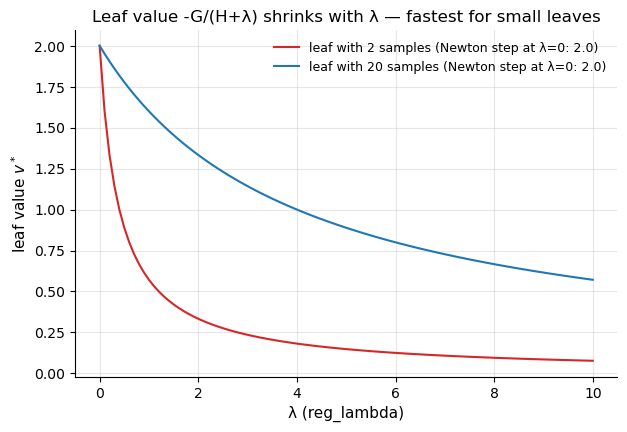

In [5]:
tree_l1 = DecisionTreeXGBoost(reg_lambda=1.0)
g_leaf = rng.normal(0.2, 0.3, size=6); h_leaf = rng.uniform(0.05, 0.25, size=6)
vs = np.linspace(-5, 5, 200001)
obj = g_leaf.sum() * vs + 0.5 * (h_leaf.sum() + 1.0) * vs**2               # Illustration only: one bracket of Eq. (2)
print(f"grid minimiser {vs[np.argmin(obj)]:+.4f} | -G/(H+λ) = {-g_leaf.sum() / (h_leaf.sum() + 1):+.4f} | "
      f"calculate_leaf_value = {tree_l1.calculate_leaf_value(g_leaf, h_leaf):+.4f}")
assert np.isclose(tree_l1.calculate_leaf_value(g_leaf, h_leaf), vs[np.argmin(obj)], atol=1e-4)

lams = np.linspace(0, 10, 101)
fig, ax = plt.subplots()
for nleaf, col in [(2, CLASS_COLORS[1]), (20, CLASS_COLORS[0])]:
    G_, H_ = -0.4 * nleaf, 0.2 * nleaf                                       # same per-sample g and h, different leaf sizes
    ax.plot(lams, [DecisionTreeXGBoost(reg_lambda=l).calculate_leaf_value(np.full(nleaf, G_ / nleaf), np.full(nleaf, H_ / nleaf)) for l in lams],
            color=col, label=f"leaf with {nleaf} samples (Newton step at λ=0: {-G_ / H_:.1f})")
ax.set(title="Leaf value -G/(H+λ) shrinks with λ — fastest for small leaves", xlabel="λ (reg_lambda)", ylabel="leaf value $v^*$"); ax.legend(); plt.show()

The repo's leaf value is the exact minimiser of the leaf's regularised quadratic. The curves show the shrinkage. Both leaves have the same per-sample gradient and Hessian, so at $\lambda = 0$ both take the Newton step $2.0$. With $\lambda = 1$, the 2-sample leaf (total curvature $H = 0.4$) is already pulled down to about $0.57$, while the 20-sample leaf ($H = 4$) keeps $1.6$. $\lambda$ acts like a prior pseudo-count of curvature at a leaf value of zero.

### 4.3 The split gain

**Math.** Splitting a leaf $I$ into $I_L$ and $I_R$ replaces one term of Eq. (4) by two, and adds one leaf (one more $\gamma$). The **reduction** in the objective is

$$
\text{Gain} = \frac12\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma . \tag{5}
$$

A split is worth keeping when its Gain is positive, that is, when the bracket exceeds $\gamma$. Compared with variance reduction, Eq. (5) weights each sample by its curvature through $H$: confident samples ($h \approx 0$) contribute their gradient but almost no "mass".

**Your implementation and check.** `compute_gain` against Eq. (5), and the gain of each candidate threshold, recomputed by brute force as the drop in Eq. (4).

In [6]:
t_gain = DecisionTreeXGBoost(reg_lambda=1.0, gamma=0.3)
for _ in range(300):
    g_ = rng.normal(size=10); h_ = rng.uniform(0.01, 0.25, 10); s = int(rng.integers(1, 10))
    GL, HL, GR, HR = g_[:s].sum(), h_[:s].sum(), g_[s:].sum(), h_[s:].sum()
    eq5 = 0.5 * (GL**2 / (HL + 1) + GR**2 / (HR + 1) - (GL + GR)**2 / (HL + HR + 1)) - 0.3
    obj_before = -0.5 * (GL + GR)**2 / (HL + HR + 1) + 0.3 * 1           # Eq. (4), one leaf
    obj_after = -0.5 * (GL**2 / (HL + 1) + GR**2 / (HR + 1)) + 0.3 * 2   # Eq. (4), two leaves
    assert np.isclose(t_gain.compute_gain(GL, HL, GR, HR, GL + GR, HL + HR), eq5)
    assert np.isclose(eq5, obj_before - obj_after)
print("✓ compute_gain = Eq. (5) = the decrease of the regularised objective (Eq. 4), on 300 random splits")

✓ compute_gain = Eq. (5) = the decrease of the regularised objective (Eq. 4), on 300 random splits


### 4.4 Gradients, Hessians and the zero start

For softmax log-loss (derived in the [classification notebook](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb#4.2-The-gradient-of-cross-entropy-with-softmax:-p---y)): $g_{ik} = p_{ik} - y_{ik}$ and $h_{ik} = p_{ik}(1 - p_{ik})$. Note the sign convention. XGBoost works with the gradient itself, not its negative, which is why the leaf value has a minus sign, $-G/(H+\lambda)$. The plain gradient-boosting code works with the residual $r = -g$ and has no minus sign.

The start is $F_k^{(0)} = 0$ for every class, so every class begins at $p = 1/K$, instead of the log-prior start $\ln\pi_k$. The first rounds therefore spend part of their effort learning the class frequencies. For balanced classes this makes little difference.

> ⚠️ **Note on the implementation — differences from the xgboost library.**
> (1) The library's multiclass softmax objective uses a Hessian of $2p(1-p)$, twice the value used here, which halves its effective step relative to this code for the same $\lambda$ and $\eta$. (2) The library adds a **base score** and uses `min_child_weight` (default 1), which forbids splits that leave a child with $H < 1$. That protects against leaves made of a few confident samples. This implementation has no `min_child_weight`; $\lambda$ is its only protection against such leaves. (3) The library uses approximate or histogram split finding on large data; this code uses exact greedy search over midpoints.

### 4.5 Post-pruning with $\gamma$

**Concept.** Growing a tree greedily, one might stop as soon as the best split has negative Gain. XGBoost instead **grows first and prunes afterwards**. It splits whenever the raw gain (the bracket of Eq. 5) is positive, up to `max_depth`, and then removes splits bottom-up. A split whose two children are both leaves, and whose Gain is negative (bracket $< \gamma$), is collapsed into a single leaf with value $-G/(H+\lambda)$ computed from *all* its samples. Because pruning goes bottom-up and only collapses splits whose children are leaves, a split with negative Gain **survives if a useful split lies below it**. This is the point of post-pruning: a split can look bad on its own and still enable a very good one.

**Illustration and your implementation.** XOR-shaped gradients make the classic example. No single split helps much, but a second split inside each half helps a lot. We grow a depth-2 tree with `build_tree` (no pruning), then apply `prune_tree` for several values of $\gamma$.

In [7]:
X_x = rng.uniform(-1, 1, size=(80, 2)); y_x = (X_x[:, 0] * X_x[:, 1] < 0).astype(float)
p_x = np.full(80, 0.5); g_x = p_x - y_x; h_x = p_x * (1 - p_x)

def describe(node, depth=0):
    if node.value is not None:
        return f"{'    ' * depth}leaf {node.value:+.3f}\n"
    return (f"{'    ' * depth}X_{node.feature_index} <= {node.threshold:+.2f}   gain-γ = {node.gain:+.3f}\n"
            + describe(node.left, depth + 1) + describe(node.right, depth + 1))

for gam in [0.0, 4.0, 10.0]:
    d = DecisionTreeXGBoost(max_depth=2, reg_lambda=1.0, gamma=gam)
    grown = d.build_tree(X_x, g_x, h_x)                     # grown with raw gain > 0, nothing pruned yet
    pruned = d.prune_tree(copy.deepcopy(grown))
    print(f"γ = {gam}: {leaves(grown)} leaves grown -> {leaves(pruned)} after pruning")
    print(describe(pruned))

γ = 0.0: 4 leaves grown -> 4 after pruning
X_0 <= -0.39   gain-γ = +3.789
    X_1 <= +0.04   gain-γ = +3.568
        leaf -1.652
        leaf +0.857
    X_1 <= +0.05   gain-γ = +8.732
        leaf +1.059
        leaf -1.000

γ = 4.0: 4 leaves grown -> 3 after pruning
X_0 <= -0.39   gain-γ = -0.211
    leaf -1.231
    X_1 <= +0.05   gain-γ = +4.732
        leaf +1.059
        leaf -1.000

γ = 10.0: 4 leaves grown -> 1 after pruning
leaf -0.333



The three settings show the three possible outcomes of post-pruning:
- **$\gamma = 0$.** Every grown split has positive gain, so nothing is pruned.
- **$\gamma = 4$.** The left child's split (bracket $3.57 < 4$) has two leaf children and negative Gain, so it is collapsed into one leaf. Its value, $-1.231$, is $-G/(H+\lambda)$ of the whole left half. The **root** also has negative Gain ($-0.211$): on its own, splitting XOR data at $x_0 \le -0.39$ is barely worth anything. But it is **kept**, because its right child is a split worth $+4.73$, and pruning only collapses splits whose children are both leaves. A pre-stopping rule with the same $\gamma$ would never have made the root split, and so would never have found the good split below it.
- **$\gamma = 10$.** Every split falls below $\gamma$. Pruning collapses bottom-up until a single leaf remains, with the value $-G/(H+\lambda)$ of all 80 samples (checked below).

In [8]:
# Check — a collapsed node gets the exact value -G/(H+λ) of all its samples
d = DecisionTreeXGBoost(max_depth=2, reg_lambda=1.0, gamma=10.0)
collapsed = d.prune_tree(d.build_tree(X_x, g_x, h_x))
print(f"fully pruned tree: one leaf {collapsed.value:+.4f};  -G/(H+λ) over all 80 samples = {-g_x.sum() / (h_x.sum() + 1):+.4f}")
assert collapsed.value is not None and np.isclose(collapsed.value, -g_x.sum() / (h_x.sum() + 1))

fully pruned tree: one leaf -0.3333;  -G/(H+λ) over all 80 samples = -0.3333


> 🔧 **Fixed in the code — pruning never happened, and would have used the wrong value.**
> *Originally:* `build_tree` only split when the Gain *including* $-\gamma$ was positive. Every stored gain was therefore positive, and `prune_tree`, which looks for negative gains, never removed anything: in a check made while writing this notebook, internal-node counts were identical before and after pruning, for every $\gamma$. $\gamma$ acted only as a pre-stopping threshold, contrary to the docstring. In addition, if a node *had* been collapsed, its new value was the plain average of its two children's values instead of $-G/(H+\lambda)$.
> *Now:* trees grow on raw gain (bracket of Eq. 5 $> 0$). Every node stores $G$, $H$ and Gain $=$ bracket $- \gamma$. `prune_tree` collapses negative-Gain splits bottom-up into leaves with value $-G/(H+\lambda)$. The demonstrations above show both the pruning and the survival of an "enabling" split.

### 4.6 Row and column subsampling

- **`subsample`** $\in (0, 1]$: in every round, a random fraction of the rows is drawn (without replacement) and shared by the $K$ trees of that round. The trees are fitted on those rows, but the scores are updated for *all* rows.
- **`colsample_bylevel`** $\in (0, 1]$: for each tree and each depth level, a random fraction (at least one) of the features is drawn, and all nodes at that level search only those. If none of the drawn features can split a node, the remaining features are searched.

In [9]:
tc = DecisionTreeXGBoost(max_depth=3, colsample_bylevel=0.5, random_state=0)
Xc = rng.normal(size=(60, 6)); gc = rng.normal(size=60); hc = np.full(60, 0.25)
tc.fit(Xc, gc, hc)
print("features drawn per depth level:", {lvl: sorted(np.asarray(f).tolist()) for lvl, f in tc._level_features.items()})
used = {}
def collect(node, depth=0):
    if node.value is None:
        used.setdefault(depth, set()).add(int(node.feature_index)); collect(node.left, depth + 1); collect(node.right, depth + 1)
collect(tc.root)
print("features actually split on per level:", {k: sorted(v) for k, v in used.items()})
assert all(used[l] <= set(np.asarray(tc._level_features[l]).tolist()) for l in used)
print("✓ every node at a given depth splits on a feature from that level's draw")

features drawn per depth level: {0: [3, 4, 5], 1: [0, 4, 5], 2: [2, 3, 4]}
features actually split on per level: {0: [3], 1: [5], 2: [3, 4]}
✓ every node at a given depth splits on a feature from that level's draw


> 🔧 **Fixed in the code — `colsample_bylevel` sampled per node, and randomness used global state.**
> *Originally:* a new feature subset was drawn for **every node**. That is what the xgboost library calls `colsample_bynode`, not `bylevel`. All randomness also came from re-seeding NumPy's global generator in the model's and every tree's `__init__`, with `random_state + i*K + k if random_state`, which treated `random_state=0` as unseeded.
> *Now:* one draw per depth level per tree (cached in `_level_features`), with a fallback to the remaining features. The model and each tree own a `np.random.default_rng` generator, and the model passes each tree a seed. Refitting is reproducible, and the global state is untouched. Further fixes: `subsample` and `colsample_bylevel` are validated to lie in $(0, 1]$, and $\lambda, \gamma \ge 0$. The division in Eqs. (3)/(5) is guarded when $H + \lambda = 0$, which is possible with $\lambda = 0$ and saturated probabilities. Feature importance now sums the raw gain (bracket of Eq. 5), so splits kept with gain below $\gamma$ cannot contribute negative importance. `get_staged_predictions` uses the rounds actually fitted. `MainXGBoost.py` no longer passes `use_label_encoder`, a parameter the xgboost library has removed.

In [10]:
m1 = XGBoostClassifier(n_estimators=5, max_depth=3, subsample=0.6, colsample_bylevel=0.5, random_state=0)
m1.fit(X_tr, y_tr); a = m1.predict_proba(X_te)
m1.fit(X_tr, y_tr); b = m1.predict_proba(X_te)
np.random.seed(7); before = np.random.random(); np.random.seed(7)
XGBoostClassifier(n_estimators=3, subsample=0.5, random_state=0).fit(X_tr, y_tr); after = np.random.random()
assert np.allclose(a, b) and before == after
print("✓ random_state=0 refits reproducibly, and fitting leaves NumPy's global random state untouched")

✓ random_state=0 refits reproducibly, and fitting leaves NumPy's global random state untouched


## 5. Implementation walkthrough, in the order the code runs

```
XGBoostClassifier(n_estimators=100, max_depth=6, learning_rate=0.3, min_samp_split=2,
                  reg_lambda=1, gamma=0, subsample=1, colsample_bylevel=1, random_state=None)
  fit(X, Y):
     rng restarted from random_state;  classes_, one-hot Y;  raw = 0                   (zero start)
     for t in range(n_estimators):
         P = softmax(raw)
         rows = all, or rng.choice(n, ⌊subsample·n⌋, replace=False)
         for k in range(K):
             g = P[:,k] - Y[:,k];  h = P[:,k](1 - P[:,k])                             §4.4
             tree = DecisionTreeXGBoost(..., random_state = rng.integers(...))
             tree.fit(X[rows], g[rows], h[rows]):
                 build_tree: best split by Eq. (5) over midpoints of the level's features;
                             split if raw gain > 0; store G, H, gain-γ; leaves -G/(H+λ)   Eqs. (3), (5)
                 prune_tree: bottom-up, collapse negative-gain splits whose children are leaves  §4.5
             raw[:, k] += η · tree.predict(X)                                           (all rows)
  predict_proba(X) = softmax(η Σ_t tree_{t,k}(X));  predict = argmax
```

**`XGBoostClassifier.__init__` (XGBoost.py, lines 45–73)** validates the parameters and creates the generator. **`softmax` (75–81)** is stable softmax. **`fit` (83–163)** implements the loop above. **`predict_proba` (165–180)**, **`predict` (182–192)** and **`get_staged_predictions` (194–217)** start from zero scores, add the shrunken tree outputs, and apply softmax and argmax. **`get_feature_importance(num_features)` / `calculate_tree_importance` (219–260)** sum each split's raw gain over all trees, divided by the number of trees.

**`DecisionTreeXGBoost` (DecisionTreeXGBoost.py).** `Node` (lines 39–55) additionally stores `G` and `H`. `__init__` (58–82) validates and creates `rng`. `build_tree` (84–115) applies the stopping rules and the raw-gain test. `get_best_split` (117–171) runs the exact greedy search over midpoints with Eq. (5), keeping ties for the *last* candidate (`>=`). `compute_gain` / `_score` (173–192) implement Eq. (5) with the zero-denominator guard. `get_feature_subset` (194–206) does the per-level column sampling. `calculate_leaf_value` / `_leaf_value` (208–220) implement Eq. (3). `prune_tree` (222–243) is §4.5. `fit` (258–272) validates the inputs, resets the generator, grows the tree and prunes it.

**`MainXGBoost.py`.** Compares this model with the xgboost library's `XGBClassifier` with matching parameters on the Wine data. Exact agreement is not expected because of the differences listed in §4.4. Not run here, because it needs xgboost and scikit-learn.

## 6. Worked numerical example: one round, three classes

Nine 1-D points (labels $0,0,0,1,1,2,1,2,2$, as in the classification notebook), one round, stumps, $\lambda = 1$, $\gamma = 0$, $\eta = 0.5$.

In [11]:
x_toy = np.arange(1, 10, dtype=float).reshape(-1, 1)
y_toy = np.array([0, 0, 0, 1, 1, 2, 1, 2, 2], dtype=float)
toy = XGBoostClassifier(n_estimators=1, max_depth=1, learning_rate=0.5, reg_lambda=1.0, gamma=0.0, random_state=0)
toy.fit(x_toy, y_toy)
P0 = np.full((9, 3), 1 / 3); Y1 = np.eye(3)[y_toy.astype(int)]
G_all, H_all = None, None
for k in range(3):
    g = P0[:, k] - Y1[:, k]; h = P0[:, k] * (1 - P0[:, k]); tree = toy.trees[k][0]
    print(f"--- class {k}: g = {np.round(g, 3)},  h = {h[0]:.4f} each;  G = {g.sum():+.3f}, H = {h.sum():.3f}")
    print("    τ   |  G_L     H_L   |  G_R     H_R   | Gain (Eq. 5)")
    gains = []
    for tau in np.arange(1.5, 9, 1.0):
        L = x_toy.ravel() <= tau
        gain = tree.compute_gain(g[L].sum(), h[L].sum(), g[~L].sum(), h[~L].sum(), g.sum(), h.sum())
        gains.append(gain)
        print(f"   {tau:>3} | {g[L].sum():+.3f}  {h[L].sum():.3f} | {g[~L].sum():+.3f}  {h[~L].sum():.3f} | {gain:.4f}")
    L = x_toy.ravel() <= tree.root.threshold
    print(f"    chosen: x_0 <= {tree.root.threshold}  (max Gain {max(gains):.4f});"
          f"  leaves -G/(H+λ): left {-g[L].sum() / (h[L].sum() + 1):+.4f}, right {-g[~L].sum() / (h[~L].sum() + 1):+.4f}"
          f"  | repo: {tree.root.left.value:+.4f}, {tree.root.right.value:+.4f}")
    assert np.isclose(tree.root.left.value, -g[L].sum() / (h[L].sum() + 1)) and np.isclose(tree.root.right.value, -g[~L].sum() / (h[~L].sum() + 1))
raw1 = np.column_stack([0.5 * toy.trees[k][0].predict(x_toy) for k in range(3)])
P1 = toy.softmax(raw1)
print("\nprobabilities after one round:\n", np.round(P1, 3))
print("predicted:", P1.argmax(1).tolist(), " true:", y_toy.astype(int).tolist(), f" log-loss {log_loss(P1, y_toy):.4f}")
assert np.allclose(P1, toy.predict_proba(x_toy))

--- class 0: g = [-0.667 -0.667 -0.667  0.333  0.333  0.333  0.333  0.333  0.333],  h = 0.2222 each;  G = -0.000, H = 2.000
    τ   |  G_L     H_L   |  G_R     H_R   | Gain (Eq. 5)
   1.5 | -0.667  0.222 | +0.667  1.778 | 0.2618
   2.5 | -1.333  0.444 | +1.333  1.556 | 0.9632
   3.5 | -2.000  0.667 | +2.000  1.333 | 2.0571
   4.5 | -1.667  0.889 | +1.667  1.111 | 1.3932
   5.5 | -1.333  1.111 | +1.333  0.889 | 0.8916
   6.5 | -1.000  1.333 | +1.000  0.667 | 0.5143
   7.5 | -0.667  1.556 | +0.667  0.444 | 0.2408
   8.5 | -0.333  1.778 | +0.333  0.222 | 0.0655
    chosen: x_0 <= 3.5  (max Gain 2.0571);  leaves -G/(H+λ): left +1.2000, right -0.8571  | repo: +1.2000, -0.8571
--- class 1: g = [ 0.333  0.333  0.333 -0.667 -0.667  0.333 -0.667  0.333  0.333],  h = 0.2222 each;  G = -0.000, H = 2.000
    τ   |  G_L     H_L   |  G_R     H_R   | Gain (Eq. 5)
   1.5 | +0.333  0.222 | -0.333  1.778 | 0.0655
   2.5 | +0.667  0.444 | -0.667  1.556 | 0.2408
   3.5 | +1.000  0.667 | -1.000  1.333 | 0.

This is the same data as round 1 of the [classification notebook's worked example](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb#6.-Worked-numerical-example:-two-rounds,-three-classes), so the two methods can be compared directly:
- **Gradients and Hessians.** Starting from zero scores, every $p = \tfrac13$, so $g = +\tfrac13$ for other classes and $-\tfrac23$ for the sample's own class, and every $h = \tfrac29$. The totals are $G = 0$ (the gradients of a softmax at the start balance out) and $H = 2$.
- **Splits.** Each class's best split maximises Eq. (5): $x_0 \le 3.5$ for classes 0 and 1, and $x_0 \le 5.5$ for class 2. These are the same splits that variance reduction chose. With all $h$ equal, Eq. (5) ranks splits much as variance reduction does; the two criteria differ once the Hessians vary.
- **Leaves.** Class 0's left leaf is $-G/(H+\lambda) = 2/(0.667 + 1) = 1.2$. Plain gradient boosting gave $\tfrac23 \cdot 2/0.667 = 2.0$ for the same leaf: $\lambda = 1$ adds a full unit of "pseudo-curvature" to a leaf whose own curvature is only $0.67$, shrinking the step by 40%.
- **Result.** The predicted classes after one round are the same as plain boosting's ($x = 7$ is still wrong), but the probabilities are less extreme. Together with the zero start, that gives a higher log-loss after one round (0.73 vs 0.62). Regularisation trades speed of fitting for caution.

## 7. Visual experiments

### 7.1 $\gamma$ and $\lambda$: tree size, leaf size and generalisation

In [12]:
rows = []
for gam in [0.0, 0.5, 2.0]:
    for lam in [0.0, 1.0, 10.0]:
        m_ = XGBoostClassifier(n_estimators=40, max_depth=4, learning_rate=0.3, reg_lambda=lam, gamma=gam, random_state=1)
        m_.fit(X_tr, y_tr)
        all_trees = [t for k in m_.trees for t in m_.trees[k]]
        mean_leaves = np.mean([leaves(t.root) for t in all_trees])
        max_abs_leaf = np.max([abs(nd.value) for t in all_trees for nd in iter_nodes(t.root) if nd.value is not None])
        P_ = m_.predict_proba(X_te)
        rows.append((gam, lam, mean_leaves, max_abs_leaf, log_loss(P_, y_te), np.mean(P_.argmax(1) == y_te)))
print(" γ    λ   | mean leaves/tree | max |leaf value| | test log-loss | test acc")
for r_ in rows:
    print(f"{r_[0]:>4} {r_[1]:>4} | {r_[2]:>16.2f} | {r_[3]:>16.3f} | {r_[4]:>13.3f} | {r_[5]:.3f}")

 γ    λ   | mean leaves/tree | max |leaf value| | test log-loss | test acc
 0.0  0.0 |            14.01 |            6.980 |         1.468 | 0.779
 0.0  1.0 |             9.88 |            2.649 |         0.820 | 0.790
 0.0 10.0 |             9.47 |            1.744 |         0.617 | 0.796
 0.5  0.0 |             2.52 |            4.806 |         0.653 | 0.786
 0.5  1.0 |             2.13 |            2.547 |         0.574 | 0.800
 0.5 10.0 |             1.75 |            1.744 |         0.555 | 0.786
 2.0  0.0 |             1.52 |            6.807 |         0.589 | 0.791
 2.0  1.0 |             1.32 |            2.547 |         0.559 | 0.790
 2.0 10.0 |             1.26 |            1.719 |         0.589 | 0.784


Reading the table:
- **$\gamma$ controls tree size.** Without it, the depth-4 trees have about 10–14 leaves on average. With $\gamma = 0.5$ they have about 2, and with $\gamma = 2$ most trees are pruned to one or two leaves. Most raw gains on this data are small, so even a modest $\gamma$ removes most splits.
- **$\lambda$ controls leaf size.** The largest leaf value falls from about 7 at $\lambda = 0$ to below 2 at $\lambda = 10$. Note that $\gamma$ alone does not do this: with $\gamma = 2$ and $\lambda = 0$ the trees are tiny, but some leaves are still huge.
- **Effect on probabilities.** The unregularised model ($\lambda = \gamma = 0$) has by far the worst test log-loss: it is extremely overconfident. Either regulariser fixes most of that, and the best log-losses come from combining moderate $\gamma$ with $\lambda \ge 1$. Test **accuracy** barely changes across the table (0.78–0.80): regularisation here is mainly about trustworthy probabilities.

### 7.2 Learning curves, and a comparison with plain gradient boosting

We compare the same data, depth and $\eta$ with the [plain gradient-boosting classifier](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb). This is the one place where this notebook imports a sibling folder, and the module names do not collide.

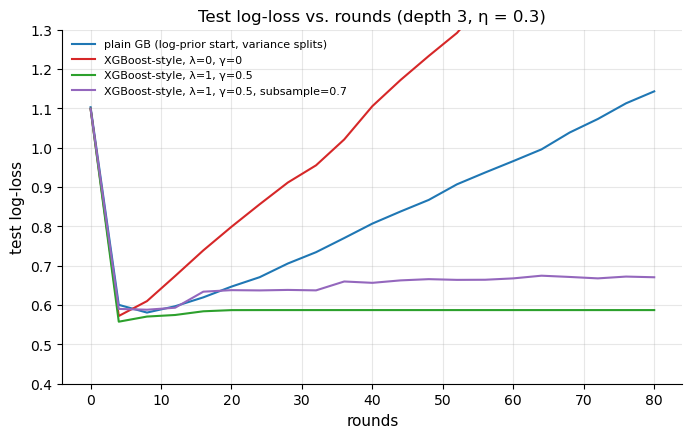

plain GB (log-prior start, variance splits) : best 0.581 at  8 rounds, final 1.143, final accuracy 0.779
XGBoost-style, λ=0, γ=0                     : best 0.572 at  4 rounds, final 1.751, final accuracy 0.771
XGBoost-style, λ=1, γ=0.5                   : best 0.558 at  4 rounds, final 0.587, final accuracy 0.797
XGBoost-style, λ=1, γ=0.5, subsample=0.7    : best 0.588 at  8 rounds, final 0.671, final accuracy 0.792


In [13]:
sys.path.insert(0, str(NB_DIR.parent / "GradientBoostClassification"))
from GradientBoost import GradientBoostingClassifier            # sibling folder's plain gradient boosting

def staged_proba_gbc(model, X, T):                               # log-prior start
    raw = np.tile(model.init_raw_scores_, (len(X), 1))
    for k in range(model.n_classes_):
        for tree in model.trees[k][:T]:
            raw[:, k] += model.learning_rate * tree.predict(X)
    return model.softmax(raw)

T_max, Ts = 80, np.arange(0, 81, 4)
models = {"plain GB (log-prior start, variance splits)": GradientBoostingClassifier(n_estimators=T_max, max_depth=3, learning_rate=0.3),
          "XGBoost-style, λ=0, γ=0": XGBoostClassifier(n_estimators=T_max, max_depth=3, learning_rate=0.3, reg_lambda=0.0, random_state=1),
          "XGBoost-style, λ=1, γ=0.5": XGBoostClassifier(n_estimators=T_max, max_depth=3, learning_rate=0.3, reg_lambda=1.0, gamma=0.5, random_state=1),
          "XGBoost-style, λ=1, γ=0.5, subsample=0.7": XGBoostClassifier(n_estimators=T_max, max_depth=3, learning_rate=0.3, reg_lambda=1.0, gamma=0.5, subsample=0.7, random_state=1)}
fig, ax = plt.subplots(figsize=(8, 4.6)); summary = {}
for (name, m_), col in zip(models.items(), CLASS_COLORS):
    m_.fit(X_tr, y_tr)
    sp = staged_proba_gbc if isinstance(m_, GradientBoostingClassifier) else staged_proba_xgb
    ll = [log_loss(sp(m_, X_te, T), y_te) for T in Ts]
    assert np.allclose(sp(m_, X_te, T_max), m_.predict_proba(X_te))
    summary[name] = (min(ll), Ts[int(np.argmin(ll))], ll[-1], np.mean(np.array(m_.predict(X_te)) == y_te))
    ax.plot(Ts, ll, color=col, label=name)
ax.set(title="Test log-loss vs. rounds (depth 3, η = 0.3)", xlabel="rounds", ylabel="test log-loss", ylim=(0.4, 1.3)); ax.legend(fontsize=8); plt.show()
for name, (best, at, last, acc_) in summary.items():
    print(f"{name:<44}: best {best:.3f} at {at:>2} rounds, final {last:.3f}, final accuracy {acc_:.3f}")

- **Plain GB and unregularised XGBoost** both reach their best log-loss within the first few rounds and then grow steadily more overconfident. The unregularised XGBoost-style model degrades fastest. Its leaves are full Newton steps, without plain GB's $(K-1)/K$ damping and without $\lambda$, so every round pushes the probabilities further.
- **$\lambda = 1$, $\gamma = 0.5$** reaches the lowest log-loss and then simply **stops changing**. Once the model fits the data, the remaining gradients are small, no split's raw gain exceeds $\gamma$, every new tree is pruned to a single leaf, and since that leaf's $G$ is near 0, its value is near 0 too. With $\gamma$, the model has a built-in brake that early stopping would otherwise have to provide.
- **Adding `subsample=0.7`** did *not* help on this small data set. Its curve is noisier and ends a little worse than without subsampling. Row subsampling is a variance-reduction device that pays off mainly on larger, noisier problems; it is not a guaranteed improvement.

### 7.3 Decision regions under strong and weak regularisation

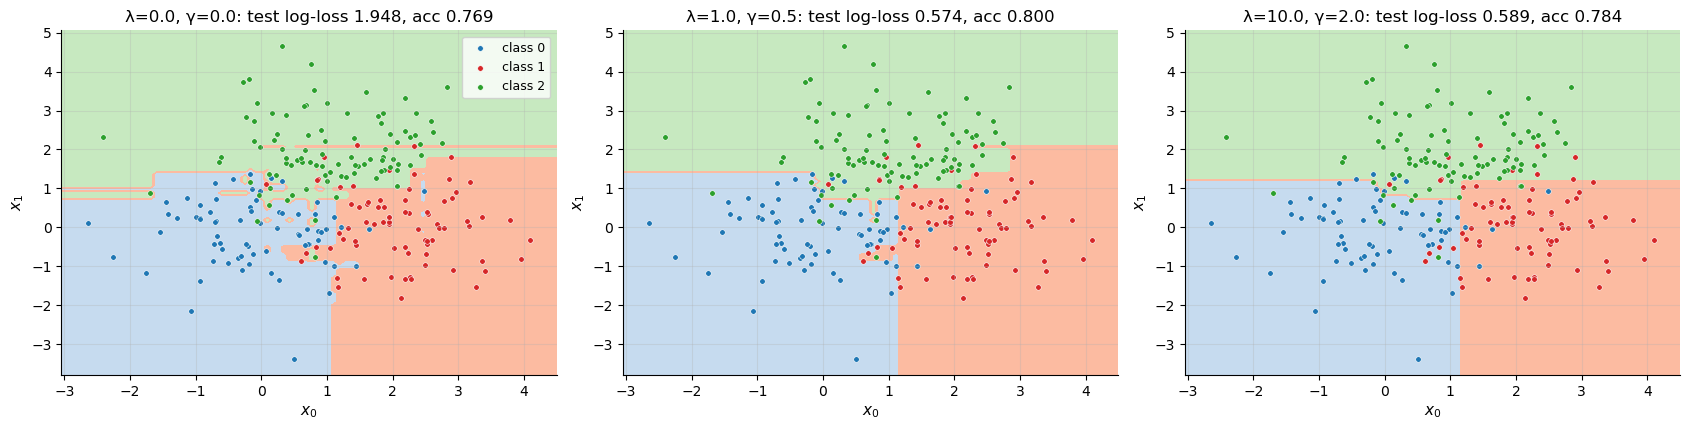

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (lam, gam) in zip(axes, [(0.0, 0.0), (1.0, 0.5), (10.0, 2.0)]):
    m_ = XGBoostClassifier(n_estimators=60, max_depth=4, learning_rate=0.3, reg_lambda=lam, gamma=gam, random_state=1); m_.fit(X_tr, y_tr)
    P_ = m_.predict_proba(X_te)
    plot_decision_regions(m_.predict, X_tr, y_tr, ax=ax, grid_n=90, legend=(lam == 0),
                          title=f"λ={lam}, γ={gam}: test log-loss {log_loss(P_, y_te):.3f}, acc {np.mean(P_.argmax(1) == y_te):.3f}")
plt.tight_layout(); plt.show()

Without regularisation (left), the boundaries develop thin slivers and notches that chase individual training points in the overlap zones, and the test log-loss is very high. With $\lambda = 1$, $\gamma = 0.5$ (middle), the regions are simple and axis-aligned, and both log-loss and accuracy are the best of the three. Heavier regularisation (right) gives even simpler boundaries at a small cost in accuracy, though its probabilities remain well-behaved. The regions show only the argmax, so much of the regularisation benefit (calibrated probabilities) is invisible here and appears in the log-loss in the titles.

## 8. Hyperparameters

| Hyperparameter | Controls | Guidance |
|---|---|---|
| `n_estimators`, `learning_rate` | number and size of steps | As in gradient boosting: small $\eta$ with more rounds; monitor validation log-loss. |
| `max_depth` | interaction order; `None` = unlimited | 3–6 typical. Pruning by $\gamma$ can only remove depth, never add it. |
| `reg_lambda` ($\lambda$) | L2 shrinkage of leaf values | Larger values give smaller, safer leaves, especially for small or confident leaves (§4.2). 1 is a common default. |
| `gamma` ($\gamma$) | minimum raw gain a split must reach to survive pruning | Larger values give smaller trees (§4.5, §7.1). Its scale depends on the loss and data, so tune it on a log grid. |
| `subsample` | fraction of rows per round | 0.5–0.9 adds randomness that often improves generalisation. |
| `colsample_bylevel` | fraction of features per depth level | Helps with many correlated features; at least 1 feature is always used. |
| `min_samp_split` | smallest splittable node | Light regularisation; the library's `min_child_weight` (not implemented) is the curvature-aware analogue. |

## 9. Complexity and limitations

**Training:** $T\cdot K$ trees. Each node evaluates every midpoint of every (sampled) feature, with $O(n_{\text{node}})$ mask sums per candidate, so a node costs $O(m\,n_{\text{node}}^2)$, the same order as the other trees in this repo. The library avoids this with **pre-sorted columns or histograms**, so that each candidate costs $O(1)$ from prefix sums of $g$ and $h$. **Prediction:** $O(T\,K\,D)$ per point.

| Limitation | Consequence | What the xgboost library does |
|---|---|---|
| Exact greedy split search, $O(m n^2)$ per node | slow beyond a few thousand rows | sorted/histogram splits with prefix sums; parallel across features |
| No `min_child_weight` | leaves of a few confident samples rely on $\lambda$ alone | `min_child_weight=1` default |
| Hessian $p(1-p)$ (library: $2p(1-p)$), zero start, no `base_score` | numerically different from the library for the same parameters | — |
| Binary problems still fit two trees per round | redundant work (see the classification notebook) | one tree on the log-odds (`binary:logistic`) |
| No early stopping, no missing-value handling | must pick $T$ by hand; NaNs unsupported | `early_stopping_rounds`; learned default directions for missing values |

Bugs found during this walkthrough and **fixed in the code**: post-pruning that never pruned, plus an averaged instead of exact merged value (§4.5); `colsample_bylevel` sampling per node (§4.6); global `np.random` seeding and the `random_state=0` quirk; division by zero when $H + \lambda = 0$; missing parameter validation; importance that could include negative gains; `get_staged_predictions` relying on `n_estimators`; `use_label_encoder` in `MainXGBoost.py`; `!= None` / `if not tree`.

## 10. Summary

- XGBoost writes each round as a **regularised objective** (Eq. 1) and expands the loss to second order. The objective then separates into one quadratic per leaf (Eq. 2).
- The optimal leaf is $-G/(H+\lambda)$ (Eq. 3), and the split gain is $\tfrac12\big[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{G^2}{H+\lambda}\big] - \gamma$ (Eq. 5): the exact decrease of the regularised objective, verified against `compute_gain` and by brute force.
- $\lambda$ shrinks leaves, most strongly for small or confident ones; $\gamma$ prunes bottom-up. A split below $\gamma$ survives if it enables a good split beneath it, as demonstrated on XOR.
- Gradients $p - y$ and Hessians $p(1-p)$ feed curvature-aware splits; row and per-level column subsampling add randomness.
- Experiments: $\gamma$ shrinks trees sharply, $\lambda$ caps leaf values, and both reduce overconfidence relative to unregularised boosting.
- Fixed during this walkthrough: real post-pruning with exact merged leaves, true per-level column sampling, private random generators, numerical guards, validation and the deprecated library argument.

This is the last notebook in the series. Taken together, the series goes from a single greedy tree, through variance reduction by averaging ([Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb)), to bias reduction by boosting ([AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb), [Gradient Boosting](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb)), and finally to a principled, regularised second-order boosting objective.